# Smart Dorm Energy Saver
**AI Fundamentals: Final Project.** Student: **Bolat Rauan**, Stream 2, Practice 2

**Problem.** In winter, many dorm rooms in Astana are heated by a 1.5 kW electric heater. Heating all day is expensive, and not heating is cold.
**Goal.** Keep the room warm while the student is home, and save money while the room is empty.

| # | Algorithm (course group) | Question it answers | Output |
|---|---|---|---|
| 1 | Hill climbing (local search) | Which daily heating schedule is best? | 8 h/day |
| 2 | Bayesian inference (probabilistic reasoning) | The sensor sees no motion: is the student home? | P(Home) = 0.321 |
| 3 | MDP, one Bellman update (sequential decision making) | Should the heater stay on? | Turn Off |

**Pipeline:** plan (hill climbing) → belief (Bayes) → action (MDP) → money saved in one simulated day.
All numbers are hypothetical assumptions, as the project guidelines allow.

▶ **To run:** *Runtime → Run all*.

## 0. Setup: imports, assumptions, printing helpers

In [1]:
"""
Smart Dorm Energy Saver — AI Fundamentals Final Project
Student: Bolat Rauan · Stream 2, Practice 2

Problem: an electric heater in a dorm room in Astana (winter). Heating all day is expensive,
not heating is cold. The agent plans the heating and switches it off when the room is empty.

Three course algorithms, one goal (warm room for less money):
  1. HILL CLIMBING (local search)  – choose the best of 5 daily heating schedules.
  2. BAYESIAN INFERENCE            – from a motion-sensor reading, infer P(student is home).
  3. MDP (one Bellman update)      – with that probability, choose Keep On or Turn Off.
  4. DAY SIMULATION                – plan (1) is corrected hour by hour by (2)+(3); money saved is reported.

All numbers are hypothetical assumptions for a toy model (allowed by the project guidelines).
Run:  python smart_dorm.py            main demonstration
      python smart_dorm.py --bonus    + 24-hour schedule hill climbing with random restarts
"""
import random
import sys

try:
    sys.stdout.reconfigure(encoding="utf-8")      # Windows console; not needed (and not available) in Colab
except AttributeError:
    pass

# assumptions
HEATER_KW = 1.5                       # heater power, kW
PRICE_TG_PER_KWH = 25                 # electricity price, tenge per kWh
COST_PER_HOUR = HEATER_KW * PRICE_TG_PER_KWH      # 37.5 tg for one hour of heating

# printing
def title(t):
    print("\n" + "=" * 74 + f"\n{t}\n" + "=" * 74)


def step1():
    title("STEP 1 · HILL CLIMBING — choose the daily heating schedule")
    print("Input: 5 schedules; cost = hours × 37.5 tg + discomfort penalty")
    print(f"{'Hours':>6s} {'Electricity':>12s} {'Discomfort':>11s} {'Total':>7s}")
    for h in SCHEDULES:
        print(f"{h:6d} {h * COST_PER_HOUR:12.1f} {DISCOMFORT[h]:11d} {schedule_cost(h):7.1f}")
    print()
    best, trace = hill_climbing(start_index=0)
    print(f"\nOutput: best schedule = {best} h/day, cost {schedule_cost(best):.1f} tg; path {' → '.join(map(str, trace))}")
    print(f"Heating hours: {', '.join(f'{h:02d}:00' for h in HOURS_OF[best])}")
    print("Why: hill climbing moves to a better neighbouring schedule until no neighbour improves the cost.")
    return best


def step2():
    title("STEP 2 · BAYES — is the student home?  (18:00 is planned ON, sensor: no motion for 30 min)")
    for motion in (False, True):
        b = bayes_home(motion)
        obs = "motion" if motion else "no motion"
        print(f"Observation: {obs}")
        print(f"  Prior       P(Home) = {b['prior']:.2f}   P(Empty) = {1 - b['prior']:.2f}")
        print(f"  Likelihood  P({obs} | Home) = {b['like_home']:.2f}   P({obs} | Empty) = {b['like_empty']:.2f}")
        print(f"  Joint       {b['like_home']:.2f}×{b['prior']:.2f} = {b['joint_home']:.3f}    "
              f"{b['like_empty']:.2f}×{1 - b['prior']:.2f} = {b['joint_empty']:.3f}")
        print(f"  Evidence    P({obs}) = {b['joint_home']:.3f} + {b['joint_empty']:.3f} = {b['evidence']:.3f}")
        print(f"  Posterior   P(Home | {obs}) = {b['joint_home']:.3f} / {b['evidence']:.3f} = {b['posterior']:.3f}")
    print("Why: Bayes' rule combines the usual habit (prior) with the new sensor evidence.")


def step3():
    title("STEP 3 · MDP — Keep On or Turn Off?")
    print("States: Home, Empty   Actions: Keep On, Turn Off   γ = 0.9, V0 = 0 (one Bellman update)")
    print(f"Reward table:  {'':9s}{'Home':>6s}{'Empty':>7s}")
    for a in ACTIONS:
        print(f"               {a:9s}{REWARD[('Home', a)]:6d}{REWARD[('Empty', a)]:7d}")
    for motion in (False, True):
        p = bayes_home(motion)["posterior"]
        action, q, _, thr = mdp_decide(p)
        print(f"\nBelief from Bayes ({'motion' if motion else 'no motion'}): P(Home) = {p:.3f}")
        for a in ACTIONS:
            print(f"  Q({a}) = {p:.3f}×({REWARD[('Home', a)]} + γ·0) + {1 - p:.3f}×({REWARD[('Empty', a)]} + γ·0) = {q[a]:+.2f}")
        print(f"  Decision → {action.upper()}   (Keep On is better only when P(Home) > {thr:.3f})")
    print("\nWhy: the MDP picks the action with the highest expected reward under uncertainty.")


def step4(best=None):
    best = best or hill_climbing(verbose=False)[0]
    title(f"STEP 4 · ONE DAY — the {best}-hour plan corrected every hour by Bayes + MDP")
    simulate_day(HOURS_OF[best])


def bonus_demo():
    title("BONUS · HILL CLIMBING ON A REAL 24-HOUR SCHEDULE (2^24 ≈ 16.8 million options)")
    bits, cost, res = bonus_hill_climbing()
    for r, steps, c in res:
        print(f"  restart {r:2d}: {steps:2d} moves → local optimum {c:7.1f}")
    print("  Best schedule: " + "".join("█" if b else "·" for b in bits) + "   (00:00 … 23:00)")
    distinct = sorted({round(c, 1) for _, _, c in res})
    print(f"  Best cost {cost:.1f}; local optima found: {distinct}")
    if len(distinct) == 1:
        print("  All restarts reached the same schedule → very likely the global optimum.")
    else:
        print("  Restarts stopped in different local optima → random restarts were needed.")


def main(bonus=False):
    print("SMART DORM ENERGY SAVER · heater in a dorm room in Astana (toy model)")
    print(f"Assumptions: heater {HEATER_KW} kW, electricity {PRICE_TG_PER_KWH} tg/kWh → {COST_PER_HOUR} tg per heating hour")
    best = step1()
    step2()
    step3()
    step4(best)
    if bonus:
        bonus_demo()


## 1. Hill climbing (local search): choose the daily schedule
- **Input:** 5 schedules (4, 6, 8, 10, 12 heating hours). Cost = hours × 37.5 tg (electricity) + discomfort penalty.
- **How it works:** start from one schedule, look at its neighbours (±2 hours), and move to the better neighbour. Stop when no neighbour is better.
- **Output:** the schedule with the lowest total cost.

In [2]:
# 1. HILL CLIMBING
# five candidate schedules (hours of heating per day), ordered so neighbours differ by 2 hours
SCHEDULES = [4, 6, 8, 10, 12]
# discomfort penalty in tenge-equivalent: fewer heating hours → colder room → bigger penalty
DISCOMFORT = {4: 400, 6: 200, 8: 90, 10: 40, 12: 20}
# which hours of the day each schedule heats (used later by the day simulation)
HOURS_OF = {
    4: [6, 7, 21, 22],
    6: [6, 7, 19, 20, 21, 22],
    8: [6, 7, 17, 18, 19, 20, 21, 22],
    10: [6, 7, 8, 16, 17, 18, 19, 20, 21, 22],
    12: [5, 6, 7, 8, 15, 16, 17, 18, 19, 20, 21, 22],
}


def schedule_cost(hours):
    """Objective to MINIMISE: electricity cost + discomfort penalty (tenge)."""
    return hours * COST_PER_HOUR + DISCOMFORT[hours]


def hill_climbing(start_index=0, verbose=True):
    """Steepest-descent hill climbing on the line of 5 schedules.
    Neighbours of schedule i are i−1 and i+1. Move to the best neighbour while it is better; stop otherwise."""
    current = start_index
    trace = [SCHEDULES[current]]
    step = 0
    if verbose:
        print(f"Start: {SCHEDULES[current]} h, cost {schedule_cost(SCHEDULES[current]):.0f} tg")
    while True:
        step += 1
        neigh = [i for i in (current - 1, current + 1) if 0 <= i < len(SCHEDULES)]
        best = min(neigh, key=lambda i: schedule_cost(SCHEDULES[i]))
        if verbose:
            shown = ", ".join(f"{SCHEDULES[i]} h = {schedule_cost(SCHEDULES[i]):.0f}" for i in neigh)
            print(f"Step {step}: at {SCHEDULES[current]} h ({schedule_cost(SCHEDULES[current]):.0f}); neighbours: {shown}")
        if schedule_cost(SCHEDULES[best]) < schedule_cost(SCHEDULES[current]):
            current = best
            trace.append(SCHEDULES[current])
            if verbose:
                print(f"        → move to {SCHEDULES[current]} h (better)")
        else:
            if verbose:
                print("        → no neighbour is better: STOP (local optimum)")
            return SCHEDULES[current], trace


In [3]:
best = step1()


STEP 1 · HILL CLIMBING — choose the daily heating schedule
Input: 5 schedules; cost = hours × 37.5 tg + discomfort penalty
 Hours  Electricity  Discomfort   Total
     4        150.0         400   550.0
     6        225.0         200   425.0
     8        300.0          90   390.0
    10        375.0          40   415.0
    12        450.0          20   470.0

Start: 4 h, cost 550 tg
Step 1: at 4 h (550); neighbours: 6 h = 425
        → move to 6 h (better)
Step 2: at 6 h (425); neighbours: 4 h = 550, 8 h = 390
        → move to 8 h (better)
Step 3: at 8 h (390); neighbours: 6 h = 425, 10 h = 415
        → no neighbour is better: STOP (local optimum)

Output: best schedule = 8 h/day, cost 390.0 tg; path 4 → 6 → 8
Heating hours: 06:00, 07:00, 17:00, 18:00, 19:00, 20:00, 21:00, 22:00
Why: hill climbing moves to a better neighbouring schedule until no neighbour improves the cost.


## 2. Bayesian inference: is the student home?
- **Input:** prior P(Home) = 0.6; sensor model P(no motion | Home) = 0.30, P(no motion | Empty) = 0.95; observation: no motion for 30 min.
- **How it works:** P(Home | obs) = P(obs | Home) · P(Home) / P(obs), where P(obs) = P(obs | Home) · P(Home) + P(obs | Empty) · P(Empty).
- **Output:** the updated probability that the student is home.

In [4]:
# 2. BAYESIAN INFERENCE
PRIOR_HOME = 0.60                     # P(Home) during heating hours (evening, from habit)
P_NOMOTION_IF_HOME = 0.30             # student sleeps / sits still at the laptop
P_NOMOTION_IF_EMPTY = 0.95            # sensor rarely sees motion in an empty room (5% false triggers)


def bayes_home(motion, prior=PRIOR_HOME):
    """P(Home | sensor reading) with every intermediate number.
    motion=True  → the sensor saw movement in the last 30 min,
    motion=False → no movement for 30 min."""
    like_home = (1 - P_NOMOTION_IF_HOME) if motion else P_NOMOTION_IF_HOME
    like_empty = (1 - P_NOMOTION_IF_EMPTY) if motion else P_NOMOTION_IF_EMPTY
    joint_home = like_home * prior
    joint_empty = like_empty * (1 - prior)
    evidence = joint_home + joint_empty
    return {
        "prior": prior, "like_home": like_home, "like_empty": like_empty,
        "joint_home": joint_home, "joint_empty": joint_empty,
        "evidence": evidence, "posterior": joint_home / evidence,
    }


In [5]:
step2()


STEP 2 · BAYES — is the student home?  (18:00 is planned ON, sensor: no motion for 30 min)
Observation: no motion
  Prior       P(Home) = 0.60   P(Empty) = 0.40
  Likelihood  P(no motion | Home) = 0.30   P(no motion | Empty) = 0.95
  Joint       0.30×0.60 = 0.180    0.95×0.40 = 0.380
  Evidence    P(no motion) = 0.180 + 0.380 = 0.560
  Posterior   P(Home | no motion) = 0.180 / 0.560 = 0.321
Observation: motion
  Prior       P(Home) = 0.60   P(Empty) = 0.40
  Likelihood  P(motion | Home) = 0.70   P(motion | Empty) = 0.05
  Joint       0.70×0.60 = 0.420    0.05×0.40 = 0.020
  Evidence    P(motion) = 0.420 + 0.020 = 0.440
  Posterior   P(Home | motion) = 0.420 / 0.440 = 0.955
Why: Bayes' rule combines the usual habit (prior) with the new sensor evidence.


## 3. MDP: Keep On or Turn Off?
- **Input:** states {Home, Empty}, actions {Keep On, Turn Off}, a reward table, transitions, γ = 0.9, V₀ = 0, and the belief from Bayes.
- **How it works:** one Bellman update, Q(s,a) = R(s,a) + γ · Σ P(s'|s) · V₀(s'). Then Q(a) = Σ b(s) · Q(s,a). Choose the action with the larger Q.
- **Output:** the action, plus the threshold probability where the decision changes.

In [6]:
# 3. MDP
STATES = ("Home", "Empty")
ACTIONS = ("Keep On", "Turn Off")
# reward for one hour (points): comfort is good, wasted energy is bad, a cold student is worst
REWARD = {
    ("Home", "Keep On"): 6,      # warm student
    ("Empty", "Keep On"): -4,    # heating an empty room = wasted money
    ("Home", "Turn Off"): -8,    # student is cold
    ("Empty", "Turn Off"): 4,    # money saved
}
# transition model: probability the room is in s' next hour (the heater does not change occupancy)
TRANSITION = {"Home": {"Home": 0.8, "Empty": 0.2}, "Empty": {"Home": 0.3, "Empty": 0.7}}
GAMMA = 0.9
V0 = {"Home": 0.0, "Empty": 0.0}      # values before the first Bellman update


def mdp_decide(p_home):
    """One Bellman update from V0 = 0, evaluated under the Bayesian belief:
         Q(s, a) = R(s, a) + γ · Σ_s' P(s'|s) · V0(s')
         Q(a)    = Σ_s b(s) · Q(s, a)        with b(Home) = p_home
    Because V0 = 0 the future term is 0 and Q(a) is the expected one-step reward."""
    belief = {"Home": p_home, "Empty": 1 - p_home}
    q_sa = {(s, a): REWARD[(s, a)] + GAMMA * sum(TRANSITION[s][s2] * V0[s2] for s2 in STATES)
            for s in STATES for a in ACTIONS}
    q = {a: sum(belief[s] * q_sa[(s, a)] for s in STATES) for a in ACTIONS}
    # threshold where both actions are equal: 6p − 4(1−p) = −8p + 4(1−p)  →  p* = 8/22
    a, b = REWARD[("Home", "Keep On")] - REWARD[("Empty", "Keep On")], REWARD[("Empty", "Keep On")]
    c, d = REWARD[("Home", "Turn Off")] - REWARD[("Empty", "Turn Off")], REWARD[("Empty", "Turn Off")]
    threshold = (d - b) / (a - c)
    return max(q, key=q.get), q, q_sa, threshold


In [7]:
step3()


STEP 3 · MDP — Keep On or Turn Off?
States: Home, Empty   Actions: Keep On, Turn Off   γ = 0.9, V0 = 0 (one Bellman update)
Reward table:             Home  Empty
               Keep On       6     -4
               Turn Off     -8      4

Belief from Bayes (no motion): P(Home) = 0.321
  Q(Keep On) = 0.321×(6 + γ·0) + 0.679×(-4 + γ·0) = -0.79
  Q(Turn Off) = 0.321×(-8 + γ·0) + 0.679×(4 + γ·0) = +0.14
  Decision → TURN OFF   (Keep On is better only when P(Home) > 0.364)

Belief from Bayes (motion): P(Home) = 0.955
  Q(Keep On) = 0.955×(6 + γ·0) + 0.045×(-4 + γ·0) = +5.55
  Q(Turn Off) = 0.955×(-8 + γ·0) + 0.045×(4 + γ·0) = -7.45
  Decision → KEEP ON   (Keep On is better only when P(Home) > 0.364)

Why: the MDP picks the action with the highest expected reward under uncertainty.


## 4. One day: the hill-climbing plan corrected every hour by Bayes + MDP

In [8]:
# 4. DAY SIMULATION
# hypothetical motion-sensor readings for one winter day (True = motion seen)
SENSOR_DAY = {5: True, 6: True, 7: True, 8: False, 15: False, 16: False, 17: True, 18: False,
              19: False, 20: True, 21: True, 22: False}


def simulate_day(hours, verbose=True):
    """For each planned heating hour: sensor → Bayes → MDP → action. Returns cost with and without the agent."""
    rows, on_hours = [], 0
    for h in hours:
        motion = SENSOR_DAY.get(h, True)
        p = bayes_home(motion)["posterior"]
        action, q, _, _ = mdp_decide(p)
        on_hours += action == "Keep On"
        rows.append((h, motion, p, action))
    planned = len(hours) * COST_PER_HOUR
    actual = on_hours * COST_PER_HOUR
    if verbose:
        print(f"{'Hour':>6s}  {'Sensor':10s} {'P(Home)':>8s}  Action")
        for h, m, p, a in rows:
            print(f"{h:4d}:00  {'motion' if m else 'no motion':10s} {p:8.3f}  {a}")
        print(f"\nPlan alone: {len(hours)} h × {COST_PER_HOUR:.1f} tg = {planned:.1f} tg")
        print(f"With agent: {on_hours} h × {COST_PER_HOUR:.1f} tg = {actual:.1f} tg")
        print(f"Saved today: {planned - actual:.1f} tg ({(planned - actual) / planned:.0%});  ≈ {(planned - actual) * 30:.0f} tg per month")
    return planned, actual, rows


In [9]:
step4(best)


STEP 4 · ONE DAY — the 8-hour plan corrected every hour by Bayes + MDP
  Hour  Sensor      P(Home)  Action
   6:00  motion        0.955  Keep On
   7:00  motion        0.955  Keep On
  17:00  motion        0.955  Keep On
  18:00  no motion     0.321  Turn Off
  19:00  no motion     0.321  Turn Off
  20:00  motion        0.955  Keep On
  21:00  motion        0.955  Keep On
  22:00  no motion     0.321  Turn Off

Plan alone: 8 h × 37.5 tg = 300.0 tg
With agent: 5 h × 37.5 tg = 187.5 tg
Saved today: 112.5 tg (38%);  ≈ 3375 tg per month


## Bonus: hill climbing on a real 24-hour schedule
There are 2²⁴ ≈ 16.8 million possible on/off schedules, too many to check one by one. A neighbour is the same schedule with one hour flipped. The search uses random restarts to avoid getting stuck in a local optimum.

In [10]:
# BONUS: 24-hour schedule
OUTSIDE_COLD = [1.0] * 6 + [0.8] * 6 + [0.6] * 6 + [0.9] * 6          # how cold each hour is (night coldest)
P_HOME_BY_HOUR = [0.95] * 8 + [0.2] * 8 + [0.7] * 8                    # usually home at night / evening
SWITCH_COST = 15                                                        # tg-equivalent per on/off switch


def bonus_cost(bits):
    """24 bits, 1 = heat this hour. Cost = energy + discomfort when off at home + switching wear."""
    energy = sum(bits) * COST_PER_HOUR
    discomfort = sum(70 * P_HOME_BY_HOUR[h] * OUTSIDE_COLD[h] for h in range(24) if not bits[h])
    switches = sum(bits[h] != bits[h - 1] for h in range(24))
    return energy + discomfort + switches * SWITCH_COST


def bonus_hill_climbing(restarts=10, seed=42):
    """Neighbour = flip one hour. Steepest descent from a random start; repeat with random restarts."""
    rng = random.Random(seed)
    best_bits, best_cost, results = None, float("inf"), []
    for r in range(restarts):
        bits = [rng.randint(0, 1) for _ in range(24)]
        cost, steps = bonus_cost(bits), 0
        while True:
            options = []
            for h in range(24):
                nb = bits[:]; nb[h] ^= 1
                options.append((bonus_cost(nb), nb))
            c, nb = min(options, key=lambda x: x[0])
            if c >= cost:
                break
            bits, cost, steps = nb, c, steps + 1
        results.append((r + 1, steps, cost))
        if cost < best_cost:
            best_bits, best_cost = bits, cost
    return best_bits, best_cost, results


In [11]:
bonus_demo()


BONUS · HILL CLIMBING ON A REAL 24-HOUR SCHEDULE (2^24 ≈ 16.8 million options)
  restart  1: 11 moves → local optimum   692.2
  restart  2: 17 moves → local optimum   692.2
  restart  3: 12 moves → local optimum   692.2
  restart  4: 16 moves → local optimum   692.2
  restart  5: 15 moves → local optimum   692.2
  restart  6:  9 moves → local optimum   692.2
  restart  7: 10 moves → local optimum   692.2
  restart  8: 17 moves → local optimum   692.2
  restart  9: 11 moves → local optimum   692.2
  restart 10: 12 moves → local optimum   692.2
  Best schedule: ████████··········██████   (00:00 … 23:00)
  Best cost 692.2; local optima found: [692.2]
  All restarts reached the same schedule → very likely the global optimum.


## Tests

In [12]:
"""Test cases for Smart Dorm Energy Saver. Run: python test_smart_dorm.py"""
import types
sd = types.SimpleNamespace(**globals())   # in Colab all functions live in this notebook


def close(a, b, tol=1e-3):
    return abs(a - b) < tol


# ---- Hill climbing
def test_hill_climbing_from_low_start():
    best, trace = sd.hill_climbing(start_index=0, verbose=False)        # start 4 h
    assert best == 8 and trace == [4, 6, 8]


def test_hill_climbing_from_high_start():
    best, trace = sd.hill_climbing(start_index=4, verbose=False)        # start 12 h
    assert best == 8 and trace == [12, 10, 8]


def test_hill_climbing_finds_true_minimum():
    assert sd.hill_climbing(verbose=False)[0] == min(sd.SCHEDULES, key=sd.schedule_cost)


# ---- Bayes
def test_bayes_no_motion():
    b = sd.bayes_home(motion=False)
    assert close(b["evidence"], 0.56) and close(b["posterior"], 0.18 / 0.56)    # 0.321


def test_bayes_motion():
    assert close(sd.bayes_home(motion=True)["posterior"], 0.42 / 0.44)          # 0.955


def test_bayes_probabilities_sum_to_one():
    b = sd.bayes_home(motion=False)
    assert close(b["joint_home"] / b["evidence"] + b["joint_empty"] / b["evidence"], 1.0)


# ---- MDP
def test_mdp_turn_off_when_probably_empty():
    action, q, _, _ = sd.mdp_decide(sd.bayes_home(motion=False)["posterior"])
    assert action == "Turn Off" and q["Turn Off"] > q["Keep On"]


def test_mdp_keep_on_when_probably_home():
    assert sd.mdp_decide(sd.bayes_home(motion=True)["posterior"])[0] == "Keep On"


def test_mdp_threshold():
    _, _, _, thr = sd.mdp_decide(0.5)
    assert close(thr, 8 / 22)
    assert sd.mdp_decide(thr + 0.01)[0] == "Keep On"
    assert sd.mdp_decide(thr - 0.01)[0] == "Turn Off"


# ---- Whole pipeline
def test_day_saves_money():
    planned, actual, rows = sd.simulate_day(sd.HOURS_OF[8], verbose=False)
    assert planned == 300 and actual == 187.5 and len(rows) == 8


def test_bonus_finds_valid_schedule():
    bits, cost, res = sd.bonus_hill_climbing(restarts=3)
    assert len(bits) == 24 and cost == min(c for _, _, c in res)


if __name__ == "__main__":
    tests = [(n, f) for n, f in globals().items() if n.startswith("test_")]
    for name, fn in tests:
        fn()
        print(f"PASS  {name}")
    print(f"\nAll {len(tests)} tests passed.")


PASS  test_hill_climbing_from_low_start
PASS  test_hill_climbing_from_high_start
PASS  test_hill_climbing_finds_true_minimum
PASS  test_bayes_no_motion
PASS  test_bayes_motion
PASS  test_bayes_probabilities_sum_to_one
PASS  test_mdp_turn_off_when_probably_empty
PASS  test_mdp_keep_on_when_probably_home
PASS  test_mdp_threshold
PASS  test_day_saves_money
PASS  test_bonus_finds_valid_schedule

All 11 tests passed.


## Overview figure

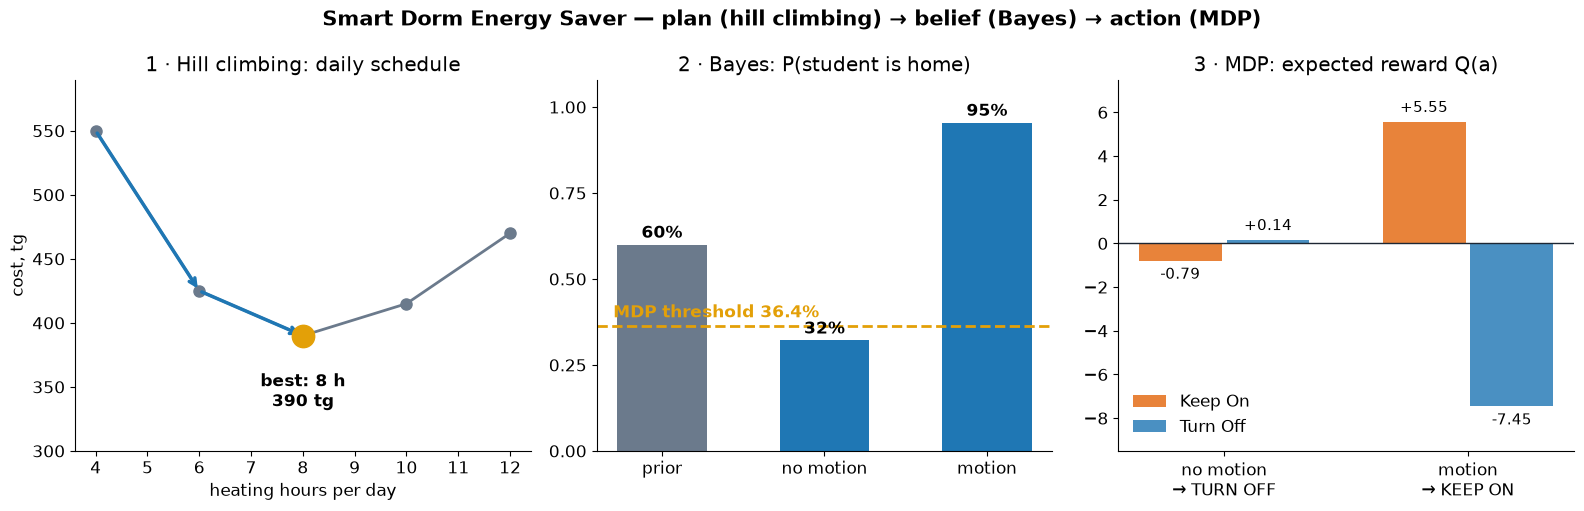

In [13]:
"""Builds smart_dorm_overview.png: one picture of the three algorithms for the README / defense."""
import matplotlib.pyplot as plt

import types
sd = types.SimpleNamespace(**globals())

INK, MUTED, BLUE, GOLD, RED, GREEN = "#1d2733", "#6b7a8c", "#1f77b4", "#e3a008", "#d64545", "#2e9e5b"
plt.rcParams.update({"font.size": 12, "axes.spines.top": False, "axes.spines.right": False})
fig, ax = plt.subplots(1, 3, figsize=(16, 5.2))

# 1. hill climbing
costs = [sd.schedule_cost(h) for h in sd.SCHEDULES]
ax[0].plot(sd.SCHEDULES, costs, "o-", color=MUTED, lw=2, ms=8)
_, trace = sd.hill_climbing(verbose=False)
for a, b in zip(trace, trace[1:]):
    ax[0].annotate("", xy=(b, sd.schedule_cost(b)), xytext=(a, sd.schedule_cost(a)),
                   arrowprops=dict(arrowstyle="->", color=BLUE, lw=2.5))
ax[0].scatter([8], [sd.schedule_cost(8)], s=260, color=GOLD, zorder=5)
ax[0].text(8, sd.schedule_cost(8) - 28, "best: 8 h\n390 tg", ha="center", va="top", weight="bold")
ax[0].set(title="1 · Hill climbing: daily schedule", xlabel="heating hours per day", ylabel="cost, tg", ylim=(300, 590))

# 2. Bayes
labels = ["prior", "no motion", "motion"]
vals = [sd.PRIOR_HOME, sd.bayes_home(False)["posterior"], sd.bayes_home(True)["posterior"]]
bars = ax[1].bar(labels, vals, color=[MUTED, BLUE, BLUE], width=0.55)
for b, v in zip(bars, vals):
    ax[1].text(b.get_x() + b.get_width() / 2, v + 0.02, f"{v:.0%}", ha="center", weight="bold")
thr = sd.mdp_decide(0.5)[3]
ax[1].axhline(thr, color=GOLD, ls="--", lw=2)
ax[1].text(-0.3, thr + 0.025, f"MDP threshold {thr:.1%}", ha="left", color=GOLD, weight="bold")
ax[1].set(title="2 · Bayes: P(student is home)", ylim=(0, 1.08), yticks=[0, .25, .5, .75, 1])

# 3. MDP
x = range(2)
for i, (motion, name) in enumerate([(False, "no motion"), (True, "motion")]):
    _, q, _, _ = sd.mdp_decide(sd.bayes_home(motion)["posterior"])
    for j, a in enumerate(sd.ACTIONS):
        v = q[a]
        ax[2].bar(i + (j - 0.5) * 0.36, v, width=0.34, color=["#e8833a", "#4a90c2"][j],
                  label=a if i == 0 else None)
        ax[2].text(i + (j - 0.5) * 0.36, v + (0.3 if v >= 0 else -0.3), f"{v:+.2f}", ha="center",
                   va="bottom" if v >= 0 else "top", fontsize=11)
ax[2].axhline(0, color=INK, lw=1)
ax[2].set_xticks(list(x), ["no motion\n→ TURN OFF", "motion\n→ KEEP ON"])
ax[2].set(title="3 · MDP: expected reward Q(a)", ylim=(-9.5, 7.5))
ax[2].legend(frameon=False, loc="lower left")

fig.suptitle("Smart Dorm Energy Saver — plan (hill climbing) → belief (Bayes) → action (MDP)", fontsize=15, weight="bold")
fig.tight_layout()
fig.savefig("smart_dorm_overview.png", dpi=150)
plt.show()


## Results and possible improvements
- On the simulated day the heater ran 5 h instead of the planned 8 h. Cost fell from 300 tg to 187.5 tg (−38%).
- **Improvements:**
  - real sensor and electricity data;
  - a separate prior for each hour;
  - several sensors combined with Naive Bayes;
  - full value iteration that models how the room cools down, so the agent can pre-heat before the student returns.

*AI use: an AI assistant (Claude) helped write and structure the code. Every calculation is printed step by step above.*